# KeySense AI — Audio Processing (Fixed)

This notebook processes the recordings in **`data/session1/` only**. It writes new results under **`dataset/session1/`** and does not overwrite your existing Session 1 dataset.

Expected input naming: one file per key, e.g. `A.wav`, `B.mp3`, … `Z.wav`. Each file may contain multiple presses of that key.

Run cells from top to bottom. First inspect the sample recording and detector settings, then run the batch-processing cell.

In [1]:
%pip install numpy matplotlib librosa sounddevice soundfile scipy scikit-learn tensorflow noisereduce pandas pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
match = re.fullmatch(r"event_(\d+)\.wav", existing.name)

In [2]:
import csv
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import noisereduce as nr
import pandas as pd
from IPython.display import Audio, display

# Session 1 only — keep Session 1 and the old dataset untouched.
DATA_DIR = Path("./data/session1")
SESSION_OUTPUT = Path("./dataset/session1")
DETECTED_ROOT = SESSION_OUTPUT / "detected"
SPECTROGRAM_ROOT = SESSION_OUTPUT / "spectrogram_images"
MANIFEST_PATH = SESSION_OUTPUT / "manifest.csv"

SAMPLE_RATE = 40000
NOISE_SECONDS = 0.8
NOISE_REDUCTION = 1
PRE_ROLL = 0.10
POST_ROLL = 0.18
MERGE_GAP = 0.12
MIN_EVENT_DURATION = 0.025
THRESHOLD_MULTIPLIER = 3.0

AUDIO_EXTENSIONS = {".wav", ".mp3", ".flac", ".m4a", ".ogg", ".aiff", ".aif"}

SESSION_OUTPUT.mkdir(parents=True, exist_ok=True)
DETECTED_ROOT.mkdir(parents=True, exist_ok=True)
SPECTROGRAM_ROOT.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_DIR.resolve()}. Check that your project has data/session1."
    )

audio_files = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS
)

print(f"Found {len(audio_files)} audio file(s) in {DATA_DIR.resolve()}")
for path in audio_files:
    print(" -", path.relative_to(DATA_DIR))

if not audio_files:
    raise RuntimeError("No supported audio files found in data/session1.")

c:\Users\My Pc\Desktop\Code\keyboard sound detection\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Found 26 audio file(s) in C:\Users\My Pc\Desktop\Code\keyboard sound detection\data\session1
 - A.mp3
 - B.mp3
 - C.mp3
 - D.mp3
 - E.mp3
 - F.mp3
 - G.mp3
 - H.mp3
 - I.mp3
 - J.mp3
 - K.mp3
 - L.mp3
 - M.mp3
 - N.mp3
 - O.mp3
 - P.mp3
 - Q.mp3
 - R.mp3
 - S.mp3
 - T.mp3
 - U.mp3
 - V.mp3
 - W.mp3
 - X.mp3
 - Y.mp3
 - Z.mp3


## 1. Inspect one recording

This cell loads the first supported file so you can inspect the waveform and spectrogram. It does not save or overwrite dataset files.

Sample file: data\session1\A.mp3
Duration: 32.26 seconds
Sample rate: 40000 Hz


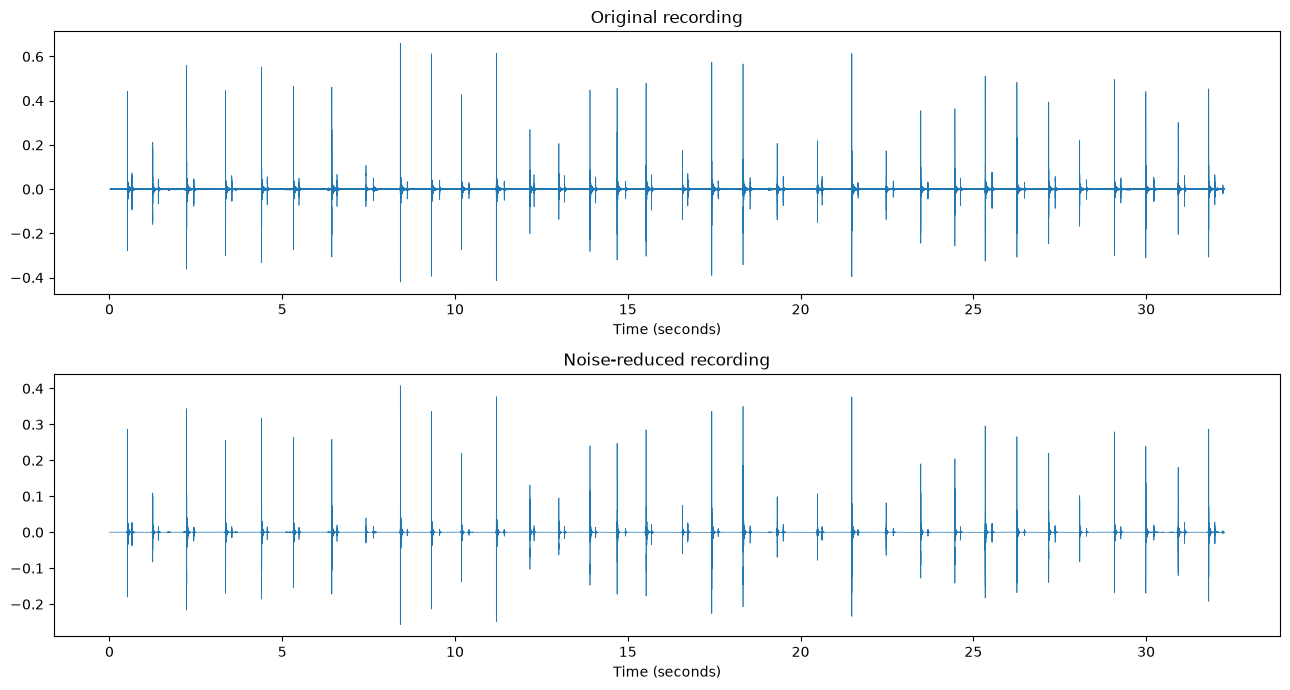

In [3]:
# Pick a sample recording for inspection.
AUDIO_FILE = audio_files[0]

y, sr = librosa.load(AUDIO_FILE, sr=SAMPLE_RATE, mono=True)
if len(y) == 0:
    raise ValueError(f"The audio file is empty: {AUDIO_FILE}")

noise_end = min(int(NOISE_SECONDS * sr), len(y))
noise_sample = y[:noise_end]

cleaned = nr.reduce_noise(
    y=y,
    sr=sr,
    y_noise=noise_sample,
    prop_decrease=NOISE_REDUCTION
)

print(f"Sample file: {AUDIO_FILE}")
print(f"Duration: {len(y) / sr:.2f} seconds")
print(f"Sample rate: {sr} Hz")

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
time_axis = np.arange(len(y)) / sr
axes[0].plot(time_axis, y, linewidth=0.5)
axes[0].set_title("Original recording")
axes[0].set_xlabel("Time (seconds)")
axes[1].plot(np.arange(len(cleaned)) / sr, cleaned, linewidth=0.5)
axes[1].set_title("Noise-reduced recording")
axes[1].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

display(Audio(y, rate=sr))
display(Audio(cleaned, rate=sr))

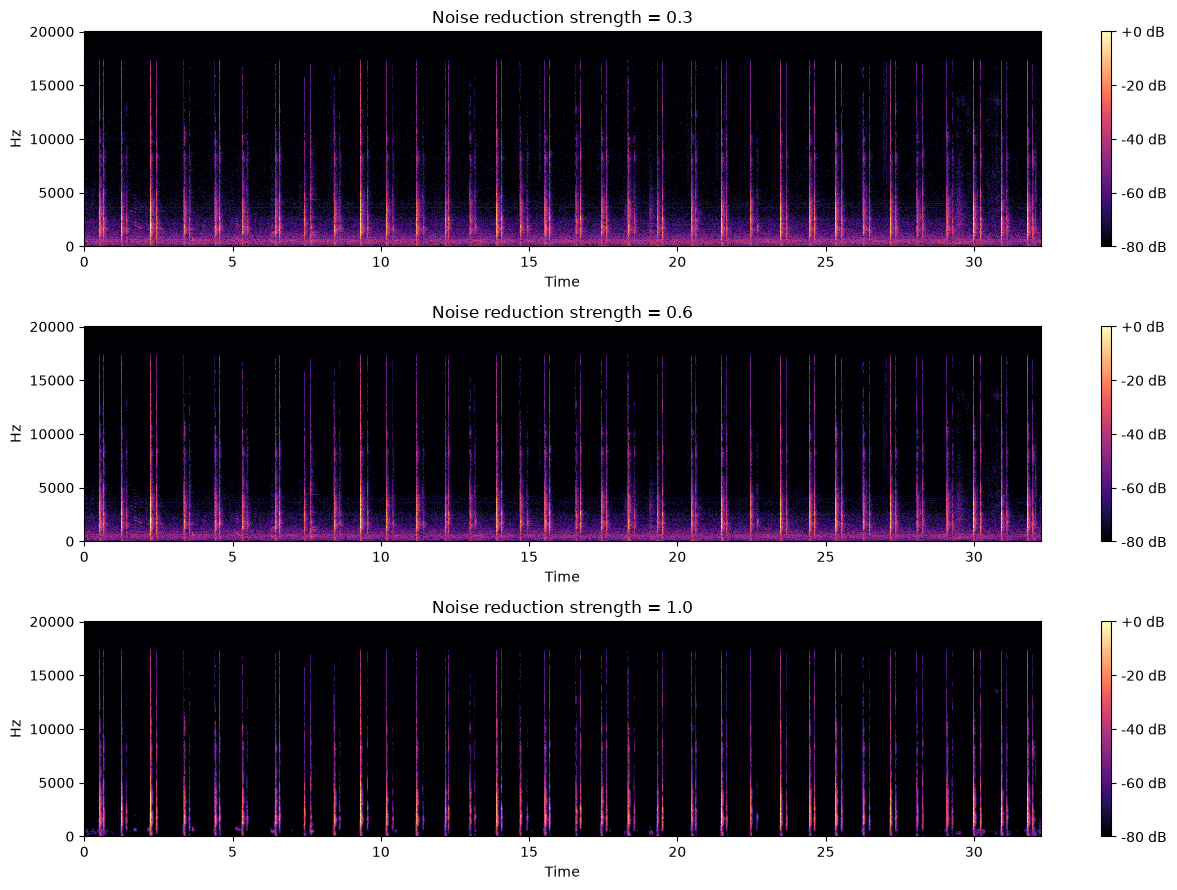

In [4]:
# Compare a few noise-reduction strengths on the sample recording.
settings = [0.3, 0.6, 1.0]
results = {}

for strength in settings:
    results[strength] = nr.reduce_noise(
        y=y,
        sr=sr,
        y_noise=noise_sample,
        prop_decrease=strength
    )

fig, axes = plt.subplots(len(settings), 1, figsize=(13, 9))
for ax, strength in zip(axes, settings):
    D = librosa.stft(results[strength], n_fft=1024, hop_length=256)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    img = librosa.display.specshow(
        S_db, sr=sr, hop_length=256,
        x_axis="time", y_axis="hz", cmap="magma", ax=ax
    )
    ax.set_title(f"Noise reduction strength = {strength}")
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout()
plt.show()

## 2. Batch-process Session 1

This is the main processing cell. It:
- reads each file in `data/session1/`;
- derives the key label from the filename stem (`A.wav` → `A`);
- detects and saves events in `dataset/session1/detected/<KEY>/`;
- saves spectrogram PNGs in `dataset/session1/spectrogram_images/<KEY>/`;
- writes `dataset/session1/manifest.csv`.

Only filenames whose stem is a single letter A–Z are processed. The script starts event numbering after any existing files for that key, so rerunning it does not overwrite already saved event files. It writes a new Session 1 manifest at the end.

In [10]:
def find_active_events(signal, sample_rate):
    # Short-time RMS energy
    frame_length = 512
    hop_length = 128

    rms = librosa.feature.rms(
        y=signal,
        frame_length=frame_length,
        hop_length=hop_length,
        center=True
    )[0]

    times = librosa.frames_to_time(
        np.arange(len(rms)),
        sr=sample_rate,
        hop_length=hop_length
    )

    # Robust threshold based on the quieter portion and the recording peak.
    noise_level = np.percentile(rms, 40)
    peak_level = np.max(rms) if len(rms) else 0.0
    threshold = max(noise_level * THRESHOLD_MULTIPLIER, peak_level * 0.04)
    active = rms > threshold

    # Merge brief gaps so downstroke/release bursts can form one event.
    max_gap_frames = max(1, int(MERGE_GAP * sample_rate / hop_length))
    active = active.copy()
    i = 0
    while i < len(active):
        if active[i]:
            i += 1
            continue
        j = i
        while j < len(active) and not active[j]:
            j += 1
        if i > 0 and j < len(active) and (j - i) <= max_gap_frames:
            active[i:j] = True
        i = j

    changes = np.diff(np.r_[False, active, False].astype(int))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    events = []
    duration = len(signal) / sample_rate
    for start_frame, end_frame in zip(starts, ends):
        start_time = max(0.0, float(times[start_frame]))
        end_time = min(duration, float(times[min(end_frame - 1, len(times) - 1)]))
        if end_time - start_time < MIN_EVENT_DURATION:
            continue

        start_sample = max(0, int((start_time - PRE_ROLL) * sample_rate))
        end_sample = min(len(signal), int((end_time + POST_ROLL) * sample_rate))
        clip = signal[start_sample:end_sample]
        if len(clip):
            events.append({
                "start": start_sample / sample_rate,
                "end": end_sample / sample_rate,
                "audio": clip
            })
    return events


def save_spectrogram(clip, sample_rate, destination):
    # Keep a consistent image size for the CNN input pipeline.
    D = librosa.stft(clip, n_fft=512, hop_length=128)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
    librosa.display.specshow(
        S_db, sr=sample_rate, hop_length=128,
        x_axis=None, y_axis=None, cmap="gray", ax=ax
    )
    ax.set_axis_off()
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    fig.savefig(destination, dpi=100, bbox_inches=None, pad_inches=0)
    plt.close(fig)


manifest_rows = []
skipped_files = []

for audio_path in audio_files:
    label = audio_path.stem.strip().upper()

    # Require one letter A-Z in the filename, e.g. A.wav.
    if not re.fullmatch(r"[A-Z]", label):
        skipped_files.append((str(audio_path), f"filename stem '{audio_path.stem}' is not a single A-Z letter"))
        continue

    try:
        signal, file_sr = librosa.load(audio_path, sr=SAMPLE_RATE, mono=True)
        if len(signal) == 0:
            skipped_files.append((str(audio_path), "empty audio"))
            continue

        noise_end = min(int(NOISE_SECONDS * file_sr), len(signal))
        noise_sample = signal[:noise_end]
        cleaned_signal = nr.reduce_noise(
            y=signal,
            sr=file_sr,
            y_noise=noise_sample,
            prop_decrease=NOISE_REDUCTION
        )

        events = find_active_events(cleaned_signal, file_sr)
        detected_dir = DETECTED_ROOT / label
        spectrogram_dir = SPECTROGRAM_ROOT / label
        detected_dir.mkdir(parents=True, exist_ok=True)
        spectrogram_dir.mkdir(parents=True, exist_ok=True)

        existing_ids = []
        for existing in detected_dir.glob("event_*.wav"):
            match = re.fullmatch(r"event_(\d+)\.wav", existing.name)
            if match:
                existing_ids.append(int(match.group(1)))
        next_id = max(existing_ids, default=0) + 1

        print(f"{audio_path.name}: detected {len(events)} event(s)")

        for offset, event in enumerate(events):
            event_id = next_id + offset
            wav_path = detected_dir / f"event_{event_id:03d}.wav"
            png_path = spectrogram_dir / f"event_{event_id:03d}.png"

            # Do not overwrite existing event files.
            if wav_path.exists() or png_path.exists():
                raise FileExistsError(
                    f"Output already exists for {label} event {event_id}. "
                    "Move/rename the existing Session 1 outputs or choose a fresh output folder."
                )

            sf.write(wav_path, event["audio"], file_sr)
            save_spectrogram(event["audio"], file_sr, png_path)

            manifest_rows.append({
                "image_path": str(png_path).replace("\\", "/"),
                "audio_path": str(wav_path).replace("\\", "/"),
                "source_recording": audio_path.name,
                "label": label,
                "session_id": "session1",
                "start_seconds": round(event["start"], 4),
                "end_seconds": round(event["end"], 4)
            })

    except Exception as exc:
        skipped_files.append((str(audio_path), f"{type(exc).__name__}: {exc}"))

# Save manifest only for this session.
manifest_columns = [
    "image_path", "audio_path", "source_recording", "label",
    "session_id", "start_seconds", "end_seconds"
]
manifest_df = pd.DataFrame(manifest_rows, columns=manifest_columns)
manifest_df.to_csv(MANIFEST_PATH, index=False)

print("\nFinished processing Session 1.")
print(f"Saved events/spectrograms: {len(manifest_df)}")
print(f"Manifest: {MANIFEST_PATH.resolve()}")

if not manifest_df.empty:
    print("\nSamples per key:")
    display(manifest_df.groupby("label").size().reindex(list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"), fill_value=0).rename("samples").to_frame())

if skipped_files:
    print("\nFiles skipped or failed:")
    for file_name, reason in skipped_files:
        print(f"- {file_name}: {reason}")

A.mp3: detected 30 event(s)
B.mp3: detected 28 event(s)
C.mp3: detected 22 event(s)
D.mp3: detected 33 event(s)
E.mp3: detected 30 event(s)
F.mp3: detected 17 event(s)
G.mp3: detected 31 event(s)
H.mp3: detected 27 event(s)
I.mp3: detected 32 event(s)
J.mp3: detected 32 event(s)
K.mp3: detected 27 event(s)
L.mp3: detected 35 event(s)
M.mp3: detected 22 event(s)
N.mp3: detected 28 event(s)
O.mp3: detected 30 event(s)
P.mp3: detected 29 event(s)
Q.mp3: detected 84 event(s)
R.mp3: detected 29 event(s)
S.mp3: detected 21 event(s)
T.mp3: detected 32 event(s)
U.mp3: detected 27 event(s)
V.mp3: detected 37 event(s)
W.mp3: detected 29 event(s)
X.mp3: detected 41 event(s)
Y.mp3: detected 24 event(s)
Z.mp3: detected 28 event(s)

Finished processing Session 1.
Saved events/spectrograms: 805
Manifest: C:\Users\My Pc\Desktop\Code\keyboard sound detection\dataset\session1\manifest.csv

Samples per key:


,samples
label,
A,30
B,28
C,22
D,33
E,30
F,17
G,31
H,27
I,32


## 3. Verify the generated dataset

Check the manifest and listen to a few saved events before evaluating the model. Automatic detection may split a press into multiple clips or miss quiet presses, so spot-check the output.

In [6]:
if MANIFEST_PATH.exists():
    check_df = pd.read_csv(MANIFEST_PATH)
    display(check_df.head(10))
    print("Manifest rows:", len(check_df))
    print("Labels found:", sorted(check_df["label"].dropna().unique().tolist()))

    # Listen to the first saved event if available.
    if not check_df.empty:
        sample_audio_path = Path(check_df.iloc[0]["audio_path"])
        clip, clip_sr = sf.read(sample_audio_path)
        print("Example event:", sample_audio_path)
        display(Audio(clip, rate=clip_sr))
else:
    print("Manifest has not been created yet. Run the batch-processing cell first.")

,image_path,audio_path,source_recording,label,session_id,start_seconds,end_seconds
0,dataset/session1/spectrogram_images/A/event_18...,dataset/session1/detected/A/event_181.wav,A.mp3,A,session1,0.4152,0.8392
1,dataset/session1/spectrogram_images/A/event_18...,dataset/session1/detected/A/event_182.wav,A.mp3,A,session1,1.1448,1.4600
2,dataset/session1/spectrogram_images/A/event_18...,dataset/session1/detected/A/event_183.wav,A.mp3,A,session1,2.1272,2.4616
3,dataset/session1/spectrogram_images/A/event_18...,dataset/session1/detected/A/event_184.wav,A.mp3,A,session1,3.2536,3.5784
4,dataset/session1/spectrogram_images/A/event_18...,dataset/session1/detected/A/event_185.wav,A.mp3,A,session1,4.2968,4.7528
5,dataset/session1/spectrogram_images/A/event_18...,dataset/session1/detected/A/event_186.wav,A.mp3,A,session1,5.2152,5.6712
6,dataset/session1/spectrogram_images/A/event_18...,dataset/session1/detected/A/event_187.wav,A.mp3,A,session1,6.3288,6.7720
7,dataset/session1/spectrogram_images/A/event_18...,dataset/session1/detected/A/event_188.wav,A.mp3,A,session1,8.3128,8.6472
8,dataset/session1/spectrogram_images/A/event_18...,dataset/session1/detected/A/event_189.wav,A.mp3,A,session1,9.2120,9.5432
9,dataset/session1/spectrogram_images/A/event_19...,dataset/session1/detected/A/event_190.wav,A.mp3,A,session1,10.0792,10.4040


Manifest rows: 805
Labels found: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Example event: dataset\session1\detected\A\event_181.wav


---
# 4. Evaluate the saved Session 2 model on Session 1

**Important:** This section does not train or fine-tune the model. It loads the model trained on Session 2 and evaluates it on the Session 1 spectrograms created above.

Before running these cells:
1. Run the audio-processing cells above and inspect the generated `dataset/session1/manifest.csv`.
2. Ensure the model trained on Session 2 was saved to `models/keysense_cnn.keras` and its label encoder to `models/keysense_label_encoder.joblib`.
3. Do not fit a new label encoder on Session 1. The saved Session 2 encoder defines the class-to-index mapping.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

MODEL_PATH = Path("./models/keysense_cnn.keras")
ENCODER_PATH = Path("./models/keysense_label_encoder.joblib")
SESSION1_MANIFEST = Path("./dataset/session1/manifest.csv")

for required_path in [MODEL_PATH, ENCODER_PATH, SESSION1_MANIFEST]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required file not found: {required_path}\n"
            "Make sure the Session 2 model/encoder are saved and Session 1 processing completed."
        )

cnn_session2 = tf.keras.models.load_model(MODEL_PATH)
encoder_session2 = joblib.load(ENCODER_PATH)

test_df = pd.read_csv(SESSION1_MANIFEST)
test_df = test_df.dropna(subset=["label", "image_path"]).copy()
test_df["label"] = test_df["label"].astype(str).str.strip().str.upper()
test_df = test_df[test_df["label"].isin(list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"))].reset_index(drop=True)

if test_df.empty:
    raise ValueError("Session 1 manifest has no usable labeled rows.")

# Use exactly the same 128x128 grayscale input shape as the existing CNN.
X_session1 = []
valid_rows = []
for _, row in test_df.iterrows():
    image_path = Path(str(row["image_path"]))
    if not image_path.is_absolute():
        image_path = Path(".") / image_path
    if not image_path.exists():
        # Handle manifest paths that use Windows separators.
        image_path = Path(str(row["image_path"]).replace("\\", "/"))
    if not image_path.exists():
        print(f"Skipping missing image: {row['image_path']}")
        continue
    with Image.open(image_path) as im:
        im = im.convert("L").resize((128, 128))
        arr = np.asarray(im, dtype=np.float32) / 255.0
    X_session1.append(arr[..., np.newaxis])
    valid_rows.append(row)

if not X_session1:
    raise ValueError("No Session 1 spectrogram images could be loaded.")

test_df = pd.DataFrame(valid_rows).reset_index(drop=True)
X_session1 = np.asarray(X_session1, dtype=np.float32)

# Match Session 1 labels (A, B, C...) to Session 2 encoder classes (A.MP3, B.MP3...)
import re

def normalize_key_label(label):
    return re.sub(r"\.(MP3|WAV)$", "", str(label).strip().upper())

label_to_index = {
    normalize_key_label(class_name): index
    for index, class_name in enumerate(encoder_session2.classes_)
}

test_df["label"] = test_df["label"].apply(normalize_key_label)

unknown_labels = sorted(set(test_df["label"]) - set(label_to_index))
if unknown_labels:
    raise ValueError(f"Unknown Session 1 labels: {unknown_labels}")

y_session1 = test_df["label"].map(label_to_index).to_numpy(dtype=int)

print("Session 1 samples evaluated:", len(test_df))
print("Number of classes:", len(label_to_index))
print("Label mapping fixed successfully!")
print("Samples per key:")
display(test_df["label"].value_counts().sort_index().rename("count").to_frame()))
print("Session 1 samples evaluated:", len(test_df))
print("Samples per key:")
display(test_df["label"].value_counts().sort_index().rename("count").to_frame())


ValueError: Session 1 has labels unknown to the saved Session 2 encoder: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']

In [ ]:
# Evaluate only — no fit(), no model training, and no encoder fitting.
probabilities_session1 = cnn_session2.predict(X_session1, verbose=0)
pred_session1 = np.argmax(probabilities_session1, axis=1)

print(f"Session 1 accuracy: {accuracy_score(y_session1, pred_session1):.4f}")
print(f"Session 1 macro F1: {f1_score(y_session1, pred_session1, average='macro'):.4f}")
print("\nPer-key classification report:")
print(classification_report(
    y_session1,
    pred_session1,
    labels=np.arange(len(encoder_session2.classes_)),
    target_names=[str(c) for c in encoder_session2.classes_],
    zero_division=0
))

cm = confusion_matrix(
    y_session1,
    pred_session1,
    labels=np.arange(len(encoder_session2.classes_))
)
fig, ax = plt.subplots(figsize=(15, 13))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=encoder_session2.classes_)
disp.plot(ax=ax, xticks_rotation=90, cmap="Reds", colorbar=False, values_format="d")
ax.set_title("KeySense AI — Session 1 Evaluation (Model Trained on Session 2)")
plt.tight_layout()
plt.show()


## Interpretation notes

- This is a cross-session test only if the saved model was trained using Session 2 and Session 1 was not used for training, validation, or tuning.
- The audio event detector can miss or split key presses. Listen to a sample of the generated clips and inspect the manifest before trusting the score.
- This notebook uses the same processing code for Session 1 as the Session 2 processing notebook. If Session 2 spectrograms used different settings when the model was trained, regenerate Session 2 with matching settings or treat the score as a preprocessing-mismatch result.
- The evaluation does not save or overwrite the trained model.
